## **Prova Substitutiva • Data Analytics • POSTECH (Fase 4)**
`Vinicius de Marchi Franciscon`

# Previsão do preço do petróleo Brent em dólar

Modelo preditivo para apoiar a tomada de decisão numa grande empresa de petróleo, com aplicação em Streamlit.

**Este notebook é construído por fases.** Esta é a **Fase 1: entendimento dos dados (EDA)**. A modelagem entra nas fases seguintes, neste mesmo arquivo.

| Bloco | O que responde |
|---|---|
| **1. Base** | Que dados temos, de onde vêm e se são confiáveis |
| **2. EDA do Brent** | Como o preço se comporta: altos, baixos, quedas, instabilidade e eventos |
| **3. Fatores externos** | O que o dólar e os estoques dos EUA dizem sobre o Brent |
| **4. Padrões** | Tendência, sazonalidade de calendário e memória da série |
| **5. Leitura para a modelagem** | O que a EDA decide para as próximas fases |

**Convenções:** `VAR` = variação percentual. `DESV_PAD` = desvio padrão das VAR diárias numa janela (mede o quanto o preço balança no dia a dia). Preços em **US$ por barril**.

## Bloco 1. Base de dados

In [1]:
import os, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

SEMENTE = 42
np.random.seed(SEMENTE)
H = 15                      # horizonte de previsão (dias úteis)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.32})
AZUL, VERDE, VERMELHO, CINZA, LARANJA, ROXO = "#1f4e79", "#2e7d32", "#c62828", "#616161", "#ef6c00", "#6a1b9a"

def pt(x, casas=0):
    """número no formato brasileiro (milhar com ponto, decimal com vírgula)"""
    return f"{x:,.{casas}f}".replace(",", "\x00").replace(".", ",").replace("\x00", ".")
def bolinha(cor, rotulo):
    return Line2D([], [], marker="o", ms=7.5, color=cor, ls="none", label=rotulo)
def legenda_lateral(ax, itens, titulo=None):
    ax.legend(handles=itens, loc="center left", bbox_to_anchor=(1.015, 0.5), frameon=False, fontsize=9.2, title=titulo,
              title_fontproperties={"weight": "bold", "size": 9})

# localiza 00_Base_TC a partir da pasta do notebook (funciona rodando de 01_Notebook ou da raiz)
AQUI = Path(os.getcwd())
BASE = next(p / "00_Base_TC" for p in [AQUI, AQUI.parent] if (p / "00_Base_TC").is_dir())
print(f"Pasta de dados: {BASE}")

Pasta de dados: C:\Users\vinic\OneDrive\Área de Trabalho\TC - 04 SUB\00_Base_TC


In [2]:
# 1.1 Leitura das bases
base   = pd.read_parquet(BASE / "base_modelagem_diaria.parquet").sort_values("data").reset_index(drop=True)
dolar  = pd.read_parquet(BASE / "dolar_amplo_fred.parquet").sort_values("data").reset_index(drop=True)
est    = pd.read_parquet(BASE / "estoques_crude_eia.parquet").sort_values("semana_ref").reset_index(drop=True)

# 1.2 Verificações de sanidade
assert base["data"].is_monotonic_increasing and base["data"].is_unique, "datas fora de ordem ou repetidas"
assert base.notna().all().all(), "há valores vazios na base"
assert (base["preco_usd"] > 0).all(), "há preços não positivos"
assert base["preco_usd"].between(5, 200).all(), "preço fora da escala plausível (US$ 5 a 200)"
assert (base["dolar_data_ref"] < base["data"]).all(), "dólar usa informação do próprio dia ou do futuro"
assert ((base["data"] - base["estoque_semana_ref"]).dt.days >= 6).all(), "estoque usado antes da divulgação"
assert ((base["data"] - base["estoque_semana_ref"]).dt.days <= 14).all(), "estoque desatualizado demais"

df = base[["data", "preco_usd"]].copy()
y, D = df["preco_usd"].values, pd.DatetimeIndex(df["data"])
df["VAR_1D"] = df["preco_usd"].pct_change() * 100
print("Todas as verificações passaram.")
display(pd.DataFrame({
    "Série": ["Brent (US$/barril)", "Dólar amplo (índice)", "Estoques de petróleo bruto EUA (mil barris)"],
    "Frequência": ["diária", "diária", "semanal"],
    "Observações": [pt(len(base)), pt(len(dolar)), pt(len(est))],
    "Início": [f"{D.min():%d/%m/%Y}", f"{dolar['data'].min():%d/%m/%Y}", f"{est['semana_ref'].min():%d/%m/%Y}"],
    "Fim": [f"{D.max():%d/%m/%Y}", f"{dolar['data'].max():%d/%m/%Y}", f"{est['semana_ref'].max():%d/%m/%Y}"],
    "Fonte": ["Ipeadata (origem EIA)", "Federal Reserve / FRED", "EIA"],
}).style.hide(axis="index"))

Todas as verificações passaram.


Série,Frequência,Observações,Início,Fim,Fonte
Brent (US$/barril),diária,6.634,03/01/2006,29/09/2026,Ipeadata (origem EIA)
Dólar amplo (índice),diária,5.203,02/01/2006,02/10/2026,Federal Reserve / FRED
Estoques de petróleo bruto EUA (mil barris),semanal,2.296,20/08/1982,25/09/2026,EIA


**Como a base foi montada (sem vazamento do futuro).** Cada linha é um dia de cotação do Brent. O dólar é o valor do dia útil **anterior** (D-1) e o estoque é o último **já divulgado** (a EIA publica na quarta-feira seguinte ao fim da semana; usamos a quinta, por segurança). As verificações acima garantem isso. Fontes e licenças em `00_Base_TC/FONTES.md`.

**Escolha de recorte.** Usamos de **jan/2006** em diante: é onde o dólar amplo do Federal Reserve começa, e inclui os grandes regimes recentes (crise de 2008, colapso de 2014-16, COVID, Ucrânia e o choque de 2026).

In [3]:
# 1.3 Estatísticas gerais do Brent
dd_serie = (df["preco_usd"] / df["preco_usd"].cummax() - 1) * 100
resumo = pd.DataFrame({
    "Métrica": ["Dias de cotação", "Período", "Preço mínimo", "Preço máximo", "Mediana", "Último preço",
                "VAR diária média", "DESV_PAD da VAR diária"],
    "Valor": [pt(len(df)), f"{D.min():%d/%m/%Y} a {D.max():%d/%m/%Y}",
              f"US$ {pt(y.min(), 2)} em {D[y.argmin()]:%d/%m/%Y}", f"US$ {pt(y.max(), 2)} em {D[y.argmax()]:%d/%m/%Y}",
              f"US$ {pt(np.median(y), 2)}", f"US$ {pt(y[-1], 2)} em {D[-1]:%d/%m/%Y}",
              f"{pt(df['VAR_1D'].mean(), 3)}%", f"{pt(df['VAR_1D'].std(), 2)}%"]})
display(resumo.style.hide(axis="index"))

Métrica,Valor
Dias de cotação,6.634
Período,03/01/2006 a 29/09/2026
Preço mínimo,"US$ 9,12 em 21/04/2020"
Preço máximo,"US$ 143,95 em 03/07/2008"
Mediana,"US$ 74,33"
Último preço,"US$ 113,96 em 29/09/2026"
VAR diária média,"0,051%"
DESV_PAD da VAR diária,"2,85%"


## Bloco 2. Análise exploratória do Brent

### 2.1 Eventos que movem o petróleo

A tabela abaixo reúne os eventos usados para **contextualizar** altos, baixos e quedas. Ela é uma entrada manual e transparente: cada linha tem categoria e origem da informação.

> **Nota de verificação:** os eventos de 2025 e 2026 foram conferidos em fontes web neste projeto. Os de 2008 a 2022 são fatos amplamente documentados, registrados aqui de memória do autor da análise; **confirme as datas antes da entrega final**, se for citá-las como fato.

In [4]:
# 2.1 Tabela de eventos (entrada manual e rastreável)
EV = [
 # data,        sentido,  categoria,       evento,                                                              verificação
 ("2008-07-03", "alta",   "mercado",       "Máximo histórico do período: US$ 143,95 (demanda forte, dólar fraco, pouca capacidade ociosa)", "dado da série"),
 ("2008-09-15", "queda",  "financeiro",    "Falência do Lehman Brothers: crise financeira global e colapso da demanda",                      "conhecimento geral"),
 ("2008-12-17", "alta",   "OPEP",          "OPEP anuncia corte de 2,2 milhões de barris/dia para frear a queda",                            "conhecimento geral"),
 ("2011-02-22", "alta",   "geopolítica",   "Primavera Árabe: revolta e interrupção da produção na Líbia",                                   "conhecimento geral"),
 ("2014-06-19", "queda",  "oferta",        "Topo de 2014 (US$ 115); começa o colapso por excesso de oferta (shale oil dos EUA)",            "dado da série"),
 ("2014-11-27", "queda",  "OPEP",          "OPEP decide não cortar produção: guerra por participação de mercado",                          "conhecimento geral"),
 ("2016-01-20", "queda",  "oferta",        "Mínimo do ciclo 2014-16: US$ 26 por excesso de oferta e estoques cheios",                       "dado da série"),
 ("2016-11-30", "alta",   "OPEP",          "Acordo OPEP+ de corte de produção",                                                             "conhecimento geral"),
 ("2018-10-05", "alta",   "geopolítica",   "Topo de 2018 (US$ 86), com sanções dos EUA ao Irã no radar; depois cai com oferta forte",       "dado da série"),
 ("2020-03-06", "queda",  "OPEP",          "Fracasso do acordo OPEP+ e guerra de preços Arábia Saudita x Rússia, em meio à COVID-19",       "conhecimento geral"),
 ("2020-03-11", "queda",  "demanda",       "OMS declara a pandemia de COVID-19: demanda global despenca",                                   "conhecimento geral"),
 ("2020-04-12", "alta",   "OPEP",          "Acordo OPEP+ de corte histórico de 9,7 milhões de barris/dia",                                  "conhecimento geral"),
 ("2020-04-21", "queda",  "demanda",       "Mínimo da série (US$ 9,12), um dia após o WTI fechar negativo",                                 "dado da série"),
 ("2022-02-24", "alta",   "geopolítica",   "Rússia invade a Ucrânia: risco sobre a oferta russa",                                           "conhecimento geral"),
 ("2022-03-08", "alta",   "geopolítica",   "Pico do choque (US$ 133); EUA anunciam veto ao petróleo russo",                                 "conhecimento geral"),
 ("2025-04-02", "queda",  "demanda",       "Tarifas dos EUA e OPEP+ acelera a retirada de cortes: preço cai para perto de US$ 60",          "web (pesquisa)"),
 ("2025-06-13", "alta",   "geopolítica",   "Israel ataca o Irã (guerra de 12 dias)",                                                        "web (pesquisa)"),
 ("2025-06-24", "queda",  "geopolítica",   "Cessar-fogo Israel-Irã: o prêmio de risco some em poucos dias",                                 "web (pesquisa)"),
 ("2026-03-02", "alta",   "geopolítica",   "Guerra com o Irã e fechamento do Estreito de Ormuz: Brent salta mais de 10% em um dia",         "web (pesquisa)"),
 ("2026-04-08", "queda",  "geopolítica",   "Cessar-fogo EUA-Irã anunciado, embora o tráfego no estreito siga baixo",                        "web (pesquisa)"),
 ("2026-07-08", "alta",   "geopolítica",   "EUA voltam a atacar o Irã e revertem a queda para níveis de pré-guerra",                        "web (pesquisa)"),
 ("2026-09-28", "alta",   "geopolítica",   "EUA rejeitam proposta do Irã de reabrir o Estreito de Ormuz",                                   "web (pesquisa)"),
]
eventos = pd.DataFrame(EV, columns=["data", "sentido", "categoria", "evento", "verificacao"])
eventos["data"] = pd.to_datetime(eventos["data"])
# eventos em feriado ou fim de semana (ex.: Ação de Graças, domingo) valem a partir do primeiro pregão seguinte
POS = D.searchsorted(eventos["data"])
assert ((pd.Series(D[POS]) - eventos["data"]).dt.days <= 4).all(), "evento longe de qualquer cotação"

# estudo de evento: VAR do Brent nos 5 e 20 pregões a partir do evento, contra o fechamento do pregão anterior
linhas = []
for (_, e), i0 in zip(eventos.iterrows(), POS):
    ref = y[i0 - 1]
    linhas.append({"Data": f"{e['data']:%d/%m/%Y}", "Sentido": e["sentido"], "Categoria": e["categoria"],
                   "Preço antes (US$)": ref,
                   "VAR dia (%)": (y[i0] / ref - 1) * 100,
                   "VAR 5 pregões (%)": (y[i0 + 4] / ref - 1) * 100 if i0 + 4 < len(y) else np.nan,
                   "VAR 20 pregões (%)": (y[i0 + 19] / ref - 1) * 100 if i0 + 19 < len(y) else np.nan,
                   "Evento": e["evento"][:92]})
EST_EV = pd.DataFrame(linhas)
display(EST_EV.style.hide(axis="index").format({"Preço antes (US$)": "{:.2f}", "VAR dia (%)": "{:+.1f}", "VAR 5 pregões (%)": "{:+.1f}", "VAR 20 pregões (%)": "{:+.1f}"}, na_rep="—"))

Data,Sentido,Categoria,Preço antes (US$),VAR dia (%),VAR 5 pregões (%),VAR 20 pregões (%),Evento
03/07/2008,alta,mercado,141.24,+1.9,+1.9,-8.4,"Máximo histórico do período: US$ 143,95 (demanda forte, dólar fraco, pouca capacidade ociosa"
15/09/2008,queda,financeiro,96.00,+0.0,-5.8,-2.6,Falência do Lehman Brothers: crise financeira global e colapso da demanda
17/12/2008,alta,OPEP,42.38,-1.3,-1.3,+9.1,"OPEP anuncia corte de 2,2 milhões de barris/dia para frear a queda"
22/02/2011,alta,geopolítica,103.45,-1.2,+3.3,+11.3,Primavera Árabe: revolta e interrupção da produção na Líbia
19/06/2014,queda,oferta,114.25,+0.8,+0.8,-5.8,Topo de 2014 (US$ 115); começa o colapso por excesso de oferta (shale oil dos EUA)
27/11/2014,queda,OPEP,77.39,+2.9,-7.1,-22.7,OPEP decide não cortar produção: guerra por participação de mercado
20/01/2016,queda,oferta,28.80,-9.7,-9.7,+13.7,Mínimo do ciclo 2014-16: US$ 26 por excesso de oferta e estoques cheios
30/11/2016,alta,OPEP,44.68,+7.3,+17.0,+21.2,Acordo OPEP+ de corte de produção
05/10/2018,alta,geopolítica,85.45,+0.7,-1.4,-9.5,"Topo de 2018 (US$ 86), com sanções dos EUA ao Irã no radar; depois cai com oferta forte"
06/03/2020,queda,OPEP,51.29,-11.1,-39.5,-60.5,"Fracasso do acordo OPEP+ e guerra de preços Arábia Saudita x Rússia, em meio à COVID-19"


### 2.2 O preço ao longo do tempo: altos, baixos e eventos

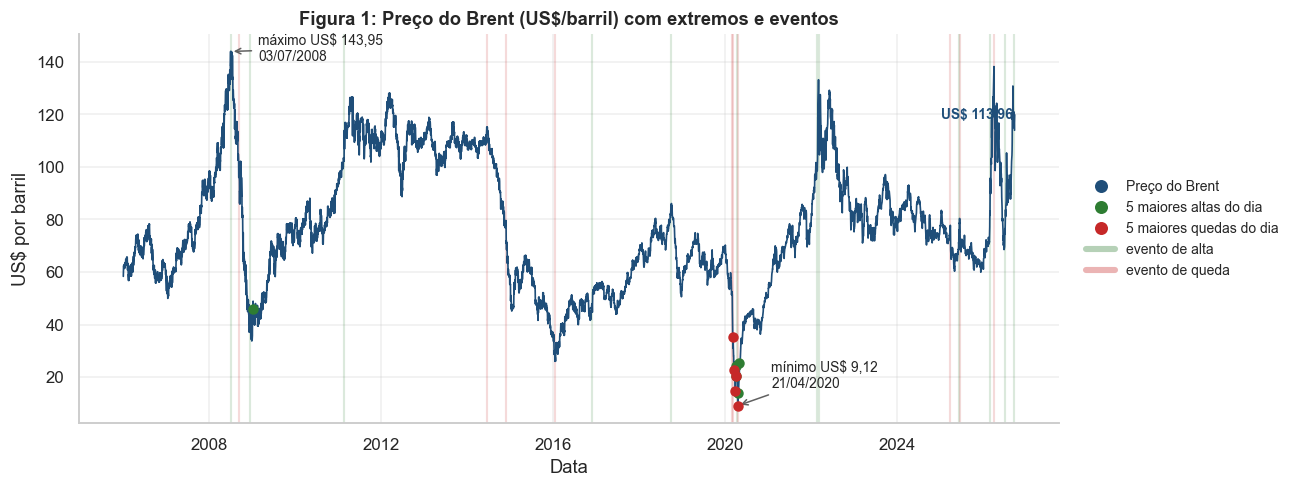

Tipo,Data,Preço (US$),VAR dia (%)
alta,22/04/2020,13.77,+51.0
alta,02/04/2020,20.24,+35.2
alta,05/01/2009,45.84,+28.0
alta,05/05/2020,25.46,+24.8
alta,03/04/2020,24.33,+20.2
queda,21/04/2020,9.12,-47.5
queda,31/03/2020,14.85,-22.6
queda,09/03/2020,35.33,-22.5
queda,09/04/2020,20.23,-19.8
queda,18/03/2020,22.79,-18.5


In [5]:
# 2.2 Figura 1: série completa, extremos, eventos e regimes
altas  = df.dropna(subset=["VAR_1D"]).nlargest(5, "VAR_1D")
baixas = df.dropna(subset=["VAR_1D"]).nsmallest(5, "VAR_1D")

fig, ax = plt.subplots(figsize=(11.5, 4.6))
ax.plot(D, y, color=AZUL, lw=1.1, zorder=3)
for _, e in eventos.iterrows():
    ax.axvline(e["data"], color=VERDE if e["sentido"] == "alta" else VERMELHO, alpha=0.17, lw=1.4, zorder=1)
ax.scatter(altas["data"],  altas["preco_usd"],  color=VERDE,    s=34, zorder=5)
ax.scatter(baixas["data"], baixas["preco_usd"], color=VERMELHO, s=34, zorder=5)
i_max, i_min = int(np.argmax(y)), int(np.argmin(y))
ax.annotate(f"máximo US$ {pt(y[i_max],2)}\n{D[i_max]:%d/%m/%Y}", (D[i_max], y[i_max]), xytext=(18, -6), textcoords="offset points",
            fontsize=9, arrowprops=dict(arrowstyle="->", color=CINZA))
ax.annotate(f"mínimo US$ {pt(y[i_min],2)}\n{D[i_min]:%d/%m/%Y}", (D[i_min], y[i_min]), xytext=(22, 12), textcoords="offset points",
            fontsize=9, arrowprops=dict(arrowstyle="->", color=CINZA))
ax.annotate(f"US$ {pt(y[-1],2)}", (D[-1], y[-1]), xytext=(-48, 8), textcoords="offset points", fontsize=9, color=AZUL, fontweight="bold")
ax.set_title("Figura 1: Preço do Brent (US$/barril) com extremos e eventos")
ax.set_xlabel("Data"); ax.set_ylabel("US$ por barril")
legenda_lateral(ax, [bolinha(AZUL, "Preço do Brent"), bolinha(VERDE, "5 maiores altas do dia"), bolinha(VERMELHO, "5 maiores quedas do dia"),
                     Line2D([], [], color=VERDE, lw=4, alpha=0.35, label="evento de alta"), Line2D([], [], color=VERMELHO, lw=4, alpha=0.35, label="evento de queda")])
plt.show()

display(pd.concat([
    altas.assign(Tipo="alta")[["Tipo", "data", "preco_usd", "VAR_1D"]],
    baixas.assign(Tipo="queda")[["Tipo", "data", "preco_usd", "VAR_1D"]]]).rename(
    columns={"data": "Data", "preco_usd": "Preço (US$)", "VAR_1D": "VAR dia (%)"}).assign(Data=lambda d: d["Data"].dt.strftime("%d/%m/%Y")).style.hide(axis="index").format({"Preço (US$)": "{:.2f}", "VAR dia (%)": "{:+.1f}"}))

### 2.3 Ano a ano

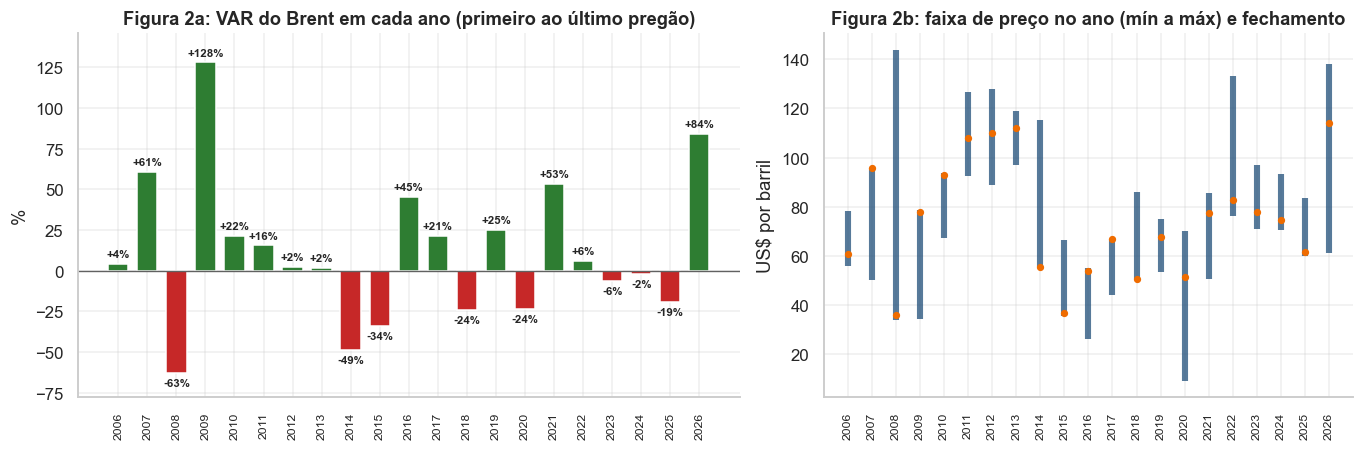

,Abertura ano,Fechamento ano,Mín,Máx,Dias,DESV_PAD dia (%),VAR ano (%)
ano,,,,,,,
2006,58.34,60.70,55.82,78.26,362,2.46,4.05
2007,59.41,95.66,49.95,95.66,359,2.22,61.02
2008,95.92,35.82,33.73,143.95,363,3.89,-62.66
2009,34.16,77.91,34.16,78.68,363,3.76,128.07
2010,76.59,93.08,67.18,93.63,364,2.27,21.53
2011,93.52,108.09,92.50,126.64,362,2.23,15.58
2012,107.54,110.04,88.69,128.14,359,1.93,2.32
2013,110.05,112.06,96.84,118.90,357,1.38,1.83
2014,107.94,55.27,55.27,115.19,361,1.50,-48.80


In [6]:
# 2.3 Figura 2: VAR por ano e faixa de preço
por_ano = df.assign(ano=D.year).groupby("ano").agg(inicio=("preco_usd", "first"), fim=("preco_usd", "last"),
                                                   minimo=("preco_usd", "min"), maximo=("preco_usd", "max"),
                                                   dias=("preco_usd", "size"), DESV_PAD_dia=("VAR_1D", "std"))
por_ano["VAR_ano"] = (por_ano["fim"] / por_ano["inicio"] - 1) * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
barras = a1.bar(por_ano.index.astype(str), por_ano["VAR_ano"], color=[VERDE if v > 0 else VERMELHO for v in por_ano["VAR_ano"]], width=0.7)
for b, v in zip(barras, por_ano["VAR_ano"]):
    a1.text(b.get_x() + b.get_width()/2, v + (3 if v > 0 else -3), f"{v:+.0f}%", ha="center", va="bottom" if v > 0 else "top", fontsize=7.5, fontweight="bold")
a1.axhline(0, color=CINZA, lw=0.9)
a1.set_title("Figura 2a: VAR do Brent em cada ano (primeiro ao último pregão)"); a1.set_ylabel("%")
a1.tick_params(axis="x", rotation=90, labelsize=8); a1.set_ylim(por_ano["VAR_ano"].min() - 15, por_ano["VAR_ano"].max() + 18)
a2.vlines(por_ano.index.astype(str), por_ano["minimo"], por_ano["maximo"], color=AZUL, lw=4, alpha=0.75)
a2.scatter(por_ano.index.astype(str), por_ano["fim"], color=LARANJA, s=14, zorder=3)
a2.set_title("Figura 2b: faixa de preço no ano (mín a máx) e fechamento"); a2.set_ylabel("US$ por barril")
a2.tick_params(axis="x", rotation=90, labelsize=8)
plt.tight_layout(); plt.show()
display(por_ano.round(2).rename(columns={"inicio": "Abertura ano", "fim": "Fechamento ano", "minimo": "Mín", "maximo": "Máx", "dias": "Dias", "DESV_PAD_dia": "DESV_PAD dia (%)", "VAR_ano": "VAR ano (%)"}))

### 2.4 Como são as variações diárias

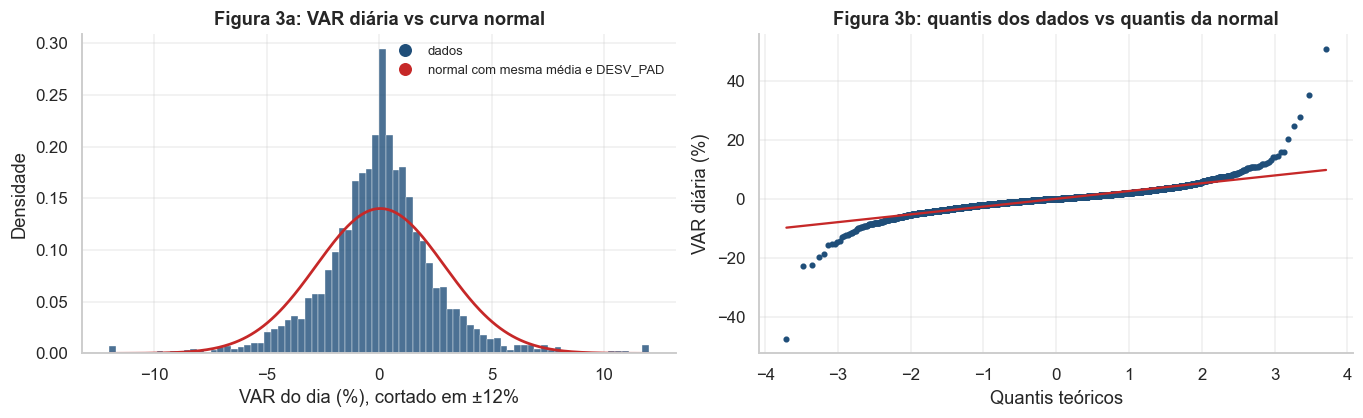

VAR diária: média +0.051%, DESV_PAD 2.85%, assimetria 0.54, curtose 36.8 (normal = 0)
Dias a mais de 3 DESV_PAD da média: 1.21% (normal: 0,27%)
Dias com |VAR| > 5%: 378 de 6633 (5.7%)


In [7]:
# 2.4 Figura 3: distribuição da VAR diária (cauda gorda)
r = df["VAR_1D"].dropna()
mu, sd = r.mean(), r.std()
assim, curt = r.skew(), r.kurt()
dentro_3dp = (np.abs(r - mu) <= 3 * sd).mean() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.9))
cortada = r.clip(-12, 12)
a1.hist(cortada, bins=80, density=True, color=AZUL, alpha=0.8, edgecolor="white", linewidth=0.3)
xx = np.linspace(-12, 12, 400); a1.plot(xx, stats.norm.pdf(xx, mu, sd), color=VERMELHO, lw=1.8)
a1.set_title("Figura 3a: VAR diária vs curva normal"); a1.set_xlabel("VAR do dia (%), cortado em ±12%"); a1.set_ylabel("Densidade")
a1.legend(handles=[bolinha(AZUL, "dados"), bolinha(VERMELHO, "normal com mesma média e DESV_PAD")], frameon=False, fontsize=8.5, loc="upper right")
stats.probplot(r, dist="norm", plot=a2)
a2.get_lines()[0].set_markersize(3); a2.get_lines()[0].set_color(AZUL); a2.get_lines()[1].set_color(VERMELHO)
a2.set_title("Figura 3b: quantis dos dados vs quantis da normal"); a2.set_xlabel("Quantis teóricos"); a2.set_ylabel("VAR diária (%)")
plt.tight_layout(); plt.show()
print(f"VAR diária: média {mu:+.3f}%, DESV_PAD {sd:.2f}%, assimetria {assim:.2f}, curtose {curt:.1f} (normal = 0)")
print(f"Dias a mais de 3 DESV_PAD da média: {100-dentro_3dp:.2f}% (normal: 0,27%)")
print(f"Dias com |VAR| > 5%: {(r.abs() > 5).sum()} de {len(r)} ({(r.abs() > 5).mean()*100:.1f}%)")

### 2.5 Queda desde a máxima de 12 meses

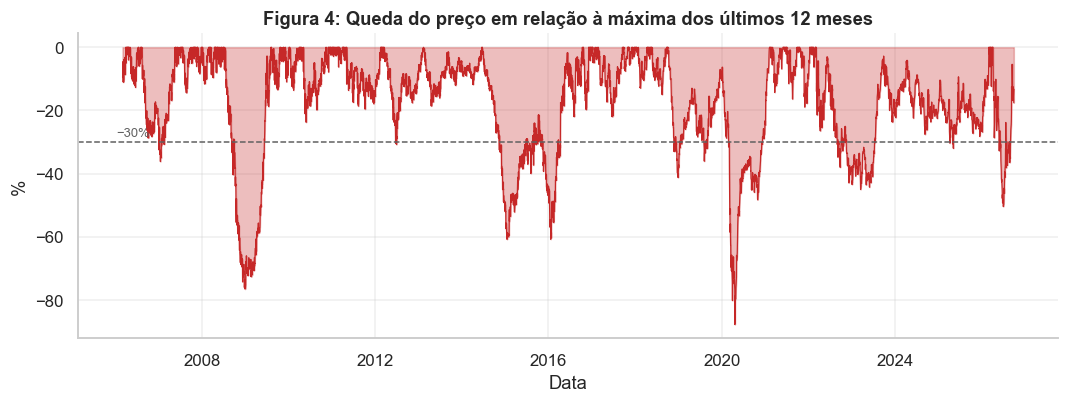

Topo,Fundo,Preço topo (US$),Preço fundo (US$),Queda (%),Pregões do topo ao fundo
09/08/2006,16/01/2007,78.26,49.95,-36.2,159
03/07/2008,30/12/2008,143.95,33.73,-76.6,178
17/03/2012,29/06/2012,128.14,88.69,-30.8,104
19/06/2014,17/01/2015,115.19,45.13,-60.8,210
05/10/2018,29/12/2018,86.07,50.57,-41.2,71
05/10/2018,07/08/2019,86.07,55.03,-36.1,233
16/05/2019,21/04/2020,74.70,9.12,-87.8,240
08/06/2022,17/03/2023,129.20,71.03,-45.0,200
05/07/2024,07/05/2025,88.66,60.31,-32.0,210
07/04/2026,02/07/2026,138.21,68.53,-50.4,60


Queda mais profunda em 12 meses: -87.8% em 03/01/2006
Máximo de 2008 (US$ 143,95) nunca foi recuperado: o pico de 2026 foi US$ 138,21


In [8]:
# 2.5 Figura 4: queda desde a máxima móvel de 252 pregões (~12 meses) e episódios
J = 252
maxj = df["preco_usd"].rolling(J, min_periods=60).max()
df["QUEDA_12M"] = (df["preco_usd"] / maxj - 1) * 100

# episódios: dias com queda <= -30%, agrupados quando separados por menos de 30 pregões
marc = (df["QUEDA_12M"] <= -30).values
episodios, i = [], 0
while i < len(marc):
    if marc[i]:
        j = i
        while j + 1 < len(marc) and (marc[j+1:j+31].any()): 
            j = j + 1 + int(np.argmax(marc[j+1:j+31]))
        seg = slice(i, j + 1)
        t = i + int(np.argmin(df["QUEDA_12M"].values[seg]))
        p = max(0, t - J) + int(np.argmax(y[max(0, t - J):t + 1]))
        episodios.append({"Topo": f"{D[p]:%d/%m/%Y}", "Fundo": f"{D[t]:%d/%m/%Y}", "Preço topo (US$)": y[p], "Preço fundo (US$)": y[t],
                          "Queda (%)": (y[t] / y[p] - 1) * 100, "Pregões do topo ao fundo": t - p})
        i = j + 1
    else:
        i += 1
EPIS = pd.DataFrame(episodios)

fig, ax = plt.subplots(figsize=(11.5, 3.6))
ax.fill_between(D, df["QUEDA_12M"], 0, color=VERMELHO, alpha=0.30)
ax.plot(D, df["QUEDA_12M"], color=VERMELHO, lw=0.8)
ax.axhline(-30, color=CINZA, ls="--", lw=1); ax.text(D[5], -29, "−30%", color=CINZA, fontsize=8.5, va="bottom")
ax.set_title("Figura 4: Queda do preço em relação à máxima dos últimos 12 meses"); ax.set_xlabel("Data"); ax.set_ylabel("%")
plt.show()
display(EPIS.style.hide(axis="index").format({"Preço topo (US$)": "{:.2f}", "Preço fundo (US$)": "{:.2f}", "Queda (%)": "{:.1f}"}))
print(f"Queda mais profunda em 12 meses: {df['QUEDA_12M'].min():.1f}% em {D[int(df['QUEDA_12M'].values.argmin())]:%d/%m/%Y}")
print(f"Máximo de 2008 (US$ 143,95) nunca foi recuperado: o pico de 2026 foi US$ {pt(df.loc[D.year == 2026, 'preco_usd'].max(), 2)}")

### 2.6 Instabilidade do preço: DESV_PAD de 30 dias

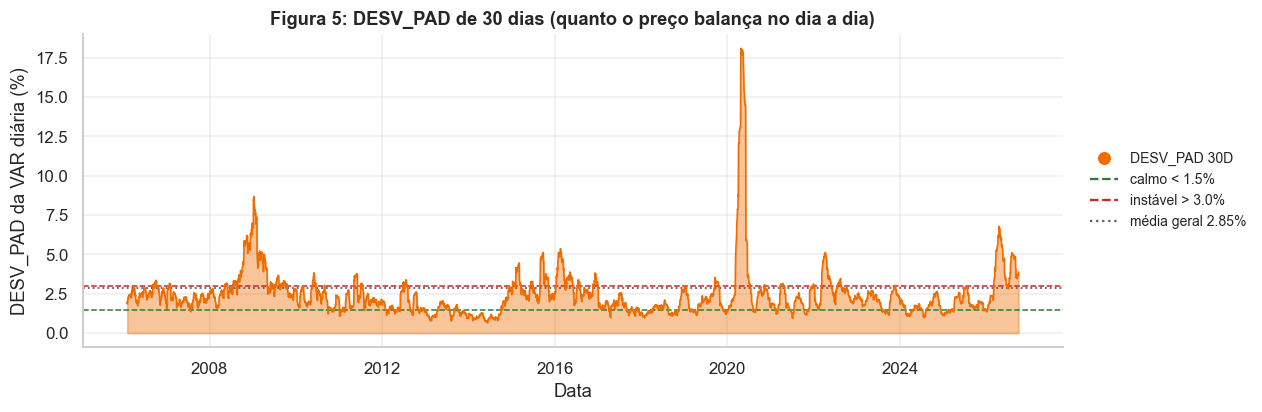

,Dias,% dos dias,|VAR| média em 15 pregões (%),"VAR 15 pregões, p10 (%)","VAR 15 pregões, p90 (%)"
regime,,,,,
calmo,1360,20.64,4.23,-6.95,6.36
moderado,3991,60.57,5.77,-8.62,9.14
instável,1238,18.79,9.61,-13.11,15.03


DESV_PAD 30D hoje: 3.90% (instável); média histórica 2.42%; máximo 18.1% em 03/01/2006


In [9]:
# 2.6 Figura 5: DESV_PAD 30D e regimes
df["DESV_PAD_30D"] = df["VAR_1D"].rolling(30).std()
q_calmo, q_alto = 1.5, 3.0   # cortes em % ao dia
df["regime"] = pd.cut(df["DESV_PAD_30D"], [-np.inf, q_calmo, q_alto, np.inf], labels=["calmo", "moderado", "instável"])

fig, ax = plt.subplots(figsize=(11.5, 3.7))
ax.fill_between(D, df["DESV_PAD_30D"], color=LARANJA, alpha=0.40, zorder=2)
ax.plot(D, df["DESV_PAD_30D"], color=LARANJA, lw=1.0, zorder=3)
ax.axhline(q_calmo, color=VERDE, ls="--", lw=1); ax.axhline(q_alto, color=VERMELHO, ls="--", lw=1)
ax.axhline(df["VAR_1D"].std(), color=CINZA, ls=":", lw=1.2)
ax.set_title("Figura 5: DESV_PAD de 30 dias (quanto o preço balança no dia a dia)")
ax.set_xlabel("Data"); ax.set_ylabel("DESV_PAD da VAR diária (%)")
legenda_lateral(ax, [bolinha(LARANJA, "DESV_PAD 30D"), Line2D([], [], color=VERDE, ls="--", label=f"calmo < {q_calmo}%"),
                     Line2D([], [], color=VERMELHO, ls="--", label=f"instável > {q_alto}%"),
                     Line2D([], [], color=CINZA, ls=":", label=f"média geral {df['VAR_1D'].std():.2f}%")])
plt.show()

# o que o regime muda no horizonte de previsão: quanto o preço anda em 15 pregões
df["VAR_15D_FUT"] = (df["preco_usd"].shift(-H) / df["preco_usd"] - 1) * 100
tab = df.dropna(subset=["DESV_PAD_30D", "VAR_15D_FUT"]).groupby("regime", observed=True).agg(
    dias=("preco_usd", "size"), perc=("preco_usd", lambda s: len(s)), VAR15_media_abs=("VAR_15D_FUT", lambda s: s.abs().mean()),
    VAR15_p10=("VAR_15D_FUT", lambda s: s.quantile(0.10)), VAR15_p90=("VAR_15D_FUT", lambda s: s.quantile(0.90)))
tab["perc"] = tab["dias"] / tab["dias"].sum() * 100
display(tab.rename(columns={"dias": "Dias", "perc": "% dos dias", "VAR15_media_abs": "|VAR| média em 15 pregões (%)",
                            "VAR15_p10": "VAR 15 pregões, p10 (%)", "VAR15_p90": "VAR 15 pregões, p90 (%)"}).round(2))
print(f"DESV_PAD 30D hoje: {df['DESV_PAD_30D'].iloc[-1]:.2f}% ({df['regime'].iloc[-1]}); média histórica {df['DESV_PAD_30D'].mean():.2f}%; máximo {df['DESV_PAD_30D'].max():.1f}% em {D[int(df['DESV_PAD_30D'].values.argmax())]:%d/%m/%Y}")

### 2.7 O que a EDA do Brent diz

## Bloco 3. Fatores externos: dólar e estoques dos EUA

Pergunta central: **dá para usar o dólar e os estoques para antecipar o Brent?** Aqui separamos duas ideias que costumam se misturar: o que *anda junto* no mesmo dia (relação contemporânea) e o que *avisa antes* (relação defasada, a única útil para prever).

### 3.1 Brent e dólar

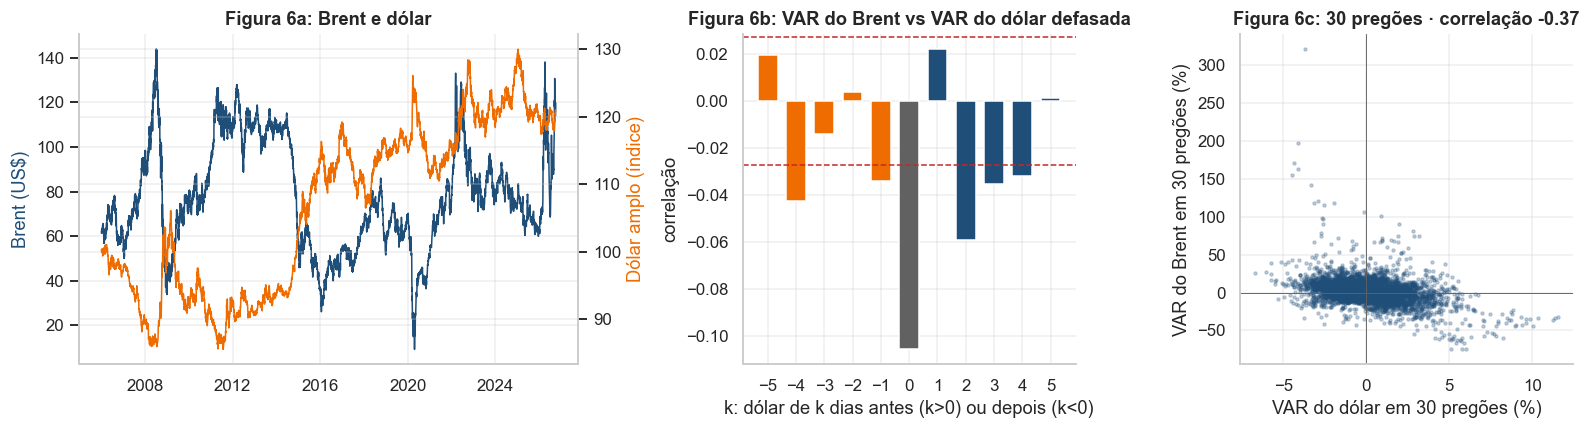

Correlação no mesmo dia: Pearson -0.106 | Spearman -0.118  (limite de ruído ±0.027, n = 5144)
Correlação com o dólar de k dias antes: {1: np.float64(0.022), 2: np.float64(-0.059), 3: np.float64(-0.035), 4: np.float64(-0.032), 5: np.float64(0.002)}


In [10]:
# 3.1 Alinhamento por data (relação contemporânea): usa a série bruta do dólar, mesma data do Brent
duas = df[["data", "preco_usd"]].merge(dolar.rename(columns={"dolar_amplo": "dolar"}), on="data", how="inner").set_index("data")
duas["VAR_B"] = duas["preco_usd"].pct_change() * 100
duas["VAR_D"] = duas["dolar"].pct_change() * 100
duas = duas.dropna()
c_dia = duas["VAR_B"].corr(duas["VAR_D"])
c_dia_sp = duas["VAR_B"].corr(duas["VAR_D"], method="spearman")

# correlação defasada: VAR do Brent hoje vs VAR do dólar k dias ANTES (k > 0 = dólar mexe primeiro)
lags = list(range(-5, 6))
cl = [duas["VAR_B"].corr(duas["VAR_D"].shift(k)) for k in lags]
n = len(duas); ic = 1.96 / np.sqrt(n)

# VAR de 30 pregões: nível de "tendência" (janelas sobrepostas, apenas ilustrativo)
duas["VAR_B30"] = (duas["preco_usd"] / duas["preco_usd"].shift(30) - 1) * 100
duas["VAR_D30"] = (duas["dolar"] / duas["dolar"].shift(30) - 1) * 100
c_30 = duas["VAR_B30"].corr(duas["VAR_D30"])

fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.0), gridspec_kw={"width_ratios": [1.5, 1, 1]})
a1 = axs[0]; a1b = a1.twinx()
a1.plot(duas.index, duas["preco_usd"], color=AZUL, lw=1.0); a1b.plot(duas.index, duas["dolar"], color=LARANJA, lw=1.0)
a1.set_ylabel("Brent (US$)", color=AZUL); a1b.set_ylabel("Dólar amplo (índice)", color=LARANJA); a1b.spines["right"].set_visible(True)
a1.set_title("Figura 6a: Brent e dólar")
axs[1].bar(lags, cl, color=[AZUL if k > 0 else (CINZA if k == 0 else LARANJA) for k in lags], width=0.7)
axs[1].axhline(ic, color=VERMELHO, ls="--", lw=1); axs[1].axhline(-ic, color=VERMELHO, ls="--", lw=1)
axs[1].set_xticks(lags); axs[1].set_xlabel("k: dólar de k dias antes (k>0) ou depois (k<0)"); axs[1].set_ylabel("correlação")
axs[1].set_title("Figura 6b: VAR do Brent vs VAR do dólar defasada")
axs[2].scatter(duas["VAR_D30"], duas["VAR_B30"], s=4, alpha=0.25, color=AZUL)
axs[2].axhline(0, color=CINZA, lw=0.6); axs[2].axvline(0, color=CINZA, lw=0.6)
axs[2].set_xlabel("VAR do dólar em 30 pregões (%)"); axs[2].set_ylabel("VAR do Brent em 30 pregões (%)")
axs[2].set_title(f"Figura 6c: 30 pregões · correlação {c_30:+.2f}")
plt.tight_layout(); plt.show()
print(f"Correlação no mesmo dia: Pearson {c_dia:+.3f} | Spearman {c_dia_sp:+.3f}  (limite de ruído ±{ic:.3f}, n = {n})")
print("Correlação com o dólar de k dias antes:", {k: round(v, 3) for k, v in zip(lags, cl) if k > 0})

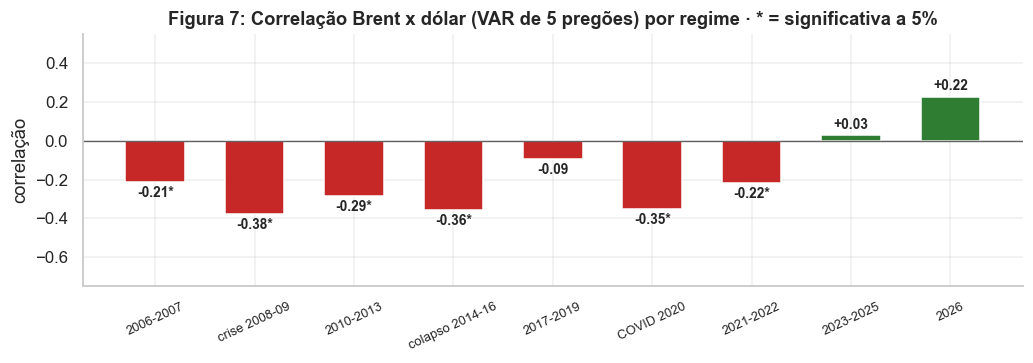

Período,Semanas,Correlação,p-valor
2006-2007,102,-0.21,0.032
crise 2008-09,102,-0.38,0.000
2010-2013,198,-0.29,0.000
colapso 2014-16,149,-0.36,0.000
2017-2019,148,-0.09,0.257
COVID 2020,48,-0.35,0.015
2021-2022,99,-0.22,0.029
2023-2025,146,+0.03,0.745
2026,36,+0.22,0.188


In [11]:
# 3.1b A relação com o dólar é estável? correlação da VAR de 5 pregões (janelas sem sobreposição) por regime histórico
PERIODOS = [("2006-2007", "2006-01-01", "2007-12-31"), ("crise 2008-09", "2008-01-01", "2009-12-31"), ("2010-2013", "2010-01-01", "2013-12-31"),
            ("colapso 2014-16", "2014-01-01", "2016-12-31"), ("2017-2019", "2017-01-01", "2019-12-31"), ("COVID 2020", "2020-01-01", "2020-12-31"),
            ("2021-2022", "2021-01-01", "2022-12-31"), ("2023-2025", "2023-01-01", "2025-12-31"), ("2026", "2026-01-01", "2026-12-31")]
sem = duas[["preco_usd", "dolar"]].iloc[::5].pct_change().dropna() * 100       # VAR de 5 pregões, sem sobreposição
linhas = []
for nome, i0, i1 in PERIODOS:
    s = sem.loc[i0:i1]
    c, p = stats.pearsonr(s["preco_usd"], s["dolar"]) if len(s) > 8 else (np.nan, np.nan)
    linhas.append({"Período": nome, "Semanas": len(s), "Correlação": c, "p-valor": p})
CORR_REG = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(9.5, 3.4))
cores = [VERMELHO if v < 0 else VERDE for v in CORR_REG["Correlação"]]
barras = ax.bar(CORR_REG["Período"], CORR_REG["Correlação"], color=cores, width=0.6)
for b, v, p in zip(barras, CORR_REG["Correlação"], CORR_REG["p-valor"]):
    ax.text(b.get_x() + b.get_width()/2, v + (0.02 if v >= 0 else -0.02), f"{v:+.2f}{'*' if p < 0.05 else ''}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, fontweight="bold")
ax.axhline(0, color=CINZA, lw=0.9); ax.set_ylim(-0.75, 0.55)
ax.set_title("Figura 7: Correlação Brent x dólar (VAR de 5 pregões) por regime · * = significativa a 5%")
ax.tick_params(axis="x", rotation=25, labelsize=8.5); ax.set_ylabel("correlação")
plt.tight_layout(); plt.show()
display(CORR_REG.style.hide(axis="index").format({"Correlação": "{:+.2f}", "p-valor": "{:.3f}"}))

### 3.2 O que o dólar diz

### 3.3 Brent e estoques de petróleo dos EUA

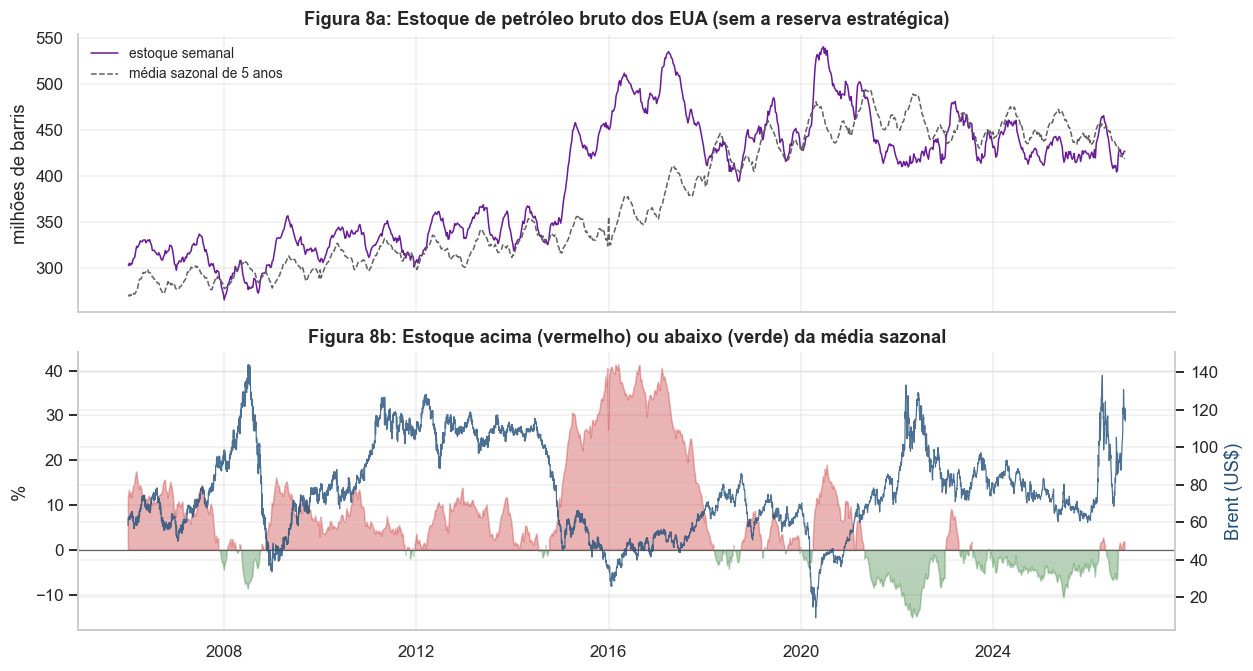

Estoque hoje: 427,3 milhões de barris, +1.9% vs média sazonal de 5 anos


In [12]:
# 3.3 Estoque vs média sazonal de 5 anos (mesma semana do ano) — sem olhar o futuro
e = est.copy()
e["sem_ano"] = e["semana_ref"].dt.isocalendar().week.astype(int).clip(upper=52)
e["ano"] = e["semana_ref"].dt.year
def media_5a(linha):
    h = e[(e["sem_ano"] == linha["sem_ano"]) & (e["ano"] < linha["ano"]) & (e["ano"] >= linha["ano"] - 5)]
    return h["estoque_mil_barris"].mean() if len(h) >= 3 else np.nan
e["media_5a"] = e.apply(media_5a, axis=1)
e["desvio_abs"] = e["estoque_mil_barris"] - e["media_5a"]
e["desvio_pct"] = e["desvio_abs"] / e["media_5a"] * 100
e["VAR_1S"] = e["estoque_mil_barris"].pct_change() * 100
e = e[e["semana_ref"] >= "2006-01-01"].reset_index(drop=True)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11.5, 6.2), sharex=True)
a1.plot(e["semana_ref"], e["estoque_mil_barris"] / 1000, color=ROXO, lw=1.0, label="estoque semanal")
a1.plot(e["semana_ref"], e["media_5a"] / 1000, color=CINZA, lw=1.0, ls="--", label="média sazonal de 5 anos")
a1.set_ylabel("milhões de barris"); a1.set_title("Figura 8a: Estoque de petróleo bruto dos EUA (sem a reserva estratégica)")
a1.legend(frameon=False, fontsize=9, loc="upper left")
a2.fill_between(e["semana_ref"], e["desvio_pct"], 0, where=e["desvio_pct"] > 0, color=VERMELHO, alpha=0.35)
a2.fill_between(e["semana_ref"], e["desvio_pct"], 0, where=e["desvio_pct"] <= 0, color=VERDE, alpha=0.35)
a2.axhline(0, color=CINZA, lw=0.8)
a2.set_ylabel("%"); a2.set_title("Figura 8b: Estoque acima (vermelho) ou abaixo (verde) da média sazonal")
a2b = a2.twinx(); a2b.plot(D, y, color=AZUL, lw=0.8, alpha=0.8); a2b.set_ylabel("Brent (US$)", color=AZUL); a2b.spines["right"].set_visible(True)
plt.tight_layout(); plt.show()
print(f"Estoque hoje: {pt(e['estoque_mil_barris'].iloc[-1]/1000, 1)} milhões de barris, {e['desvio_pct'].iloc[-1]:+.1f}% vs média sazonal de 5 anos")

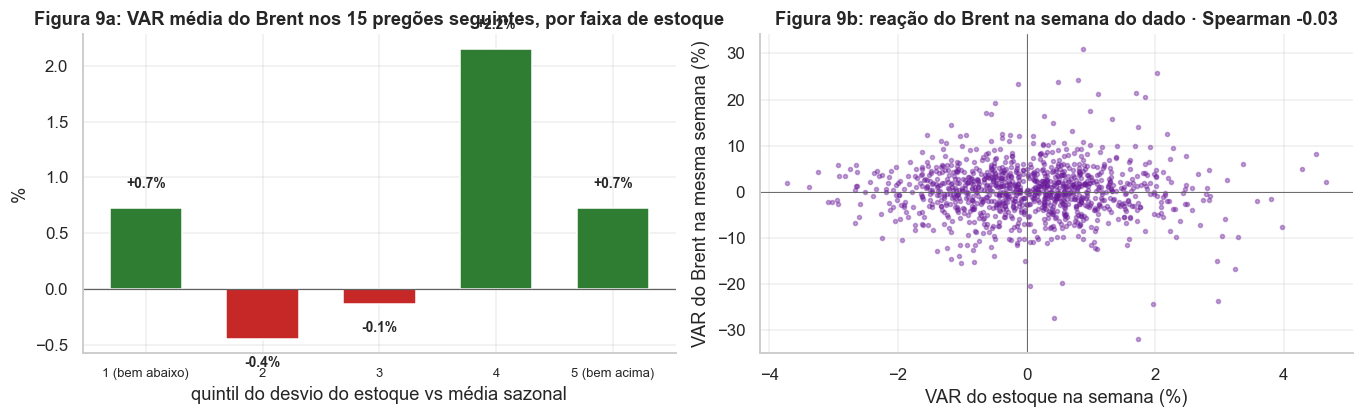

,Semanas,Desvio médio (%),VAR 15 pregões média (%),VAR 15 pregões mediana (%),% das vezes com alta
faixa,,,,,
1 (bem abaixo),216,-6.19,0.73,0.45,50.93
2,215,-0.47,-0.45,0.48,52.09
3,216,4.51,-0.14,0.30,51.39
4,215,9.67,2.16,0.97,57.67
5 (bem acima),216,25.57,0.73,0.42,52.31


Desvio sazonal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman +0.036 (p = 0.240); sem sobreposição: +0.098 (p = 0.063), n = 360
VAR semanal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman -0.008 (p = 0.782)
VAR semanal do estoque x VAR do Brent na MESMA semana: Spearman -0.031 (p = 0.317)


In [13]:
# 3.4 O estoque ajuda a prever o Brent? VAR dos 15 pregões seguintes à divulgação, por faixa de desvio sazonal
d_est = df[["data", "preco_usd", "VAR_15D_FUT"]].sort_values("data")
e2 = e.dropna(subset=["desvio_pct"]).copy()
e2 = pd.merge_asof(e2.sort_values("data_disponivel"), d_est.rename(columns={"data": "d_div"}), left_on="data_disponivel", right_on="d_div", direction="forward").dropna(subset=["VAR_15D_FUT"])
# reação na própria semana: Brent da sexta de referência até a divulgação (já aconteceu quando o dado sai)
p_ref = pd.merge_asof(e2.sort_values("semana_ref")[["semana_ref"]], d_est.rename(columns={"data": "d_ref", "preco_usd": "p_ref"})[["d_ref", "p_ref"]], left_on="semana_ref", right_on="d_ref", direction="backward")
e2 = e2.sort_values("semana_ref").reset_index(drop=True); e2["p_ref"] = p_ref["p_ref"].values
e2["VAR_semana_atual"] = (e2["preco_usd"] / e2["p_ref"] - 1) * 100

e2["faixa"] = pd.qcut(e2["desvio_pct"], 5, labels=["1 (bem abaixo)", "2", "3", "4", "5 (bem acima)"])
tb = e2.groupby("faixa", observed=True).agg(semanas=("desvio_pct", "size"), desvio_medio=("desvio_pct", "mean"),
                                            VAR15_media=("VAR_15D_FUT", "mean"), VAR15_mediana=("VAR_15D_FUT", "median"),
                                            positivo=("VAR_15D_FUT", lambda s: (s > 0).mean() * 100))
rho, p_rho = stats.spearmanr(e2["desvio_pct"], e2["VAR_15D_FUT"])
sub = e2.iloc[::3]                                   # a cada 3 semanas: janelas de 15 pregões não se sobrepõem
rho_s, p_rho_s = stats.spearmanr(sub["desvio_pct"], sub["VAR_15D_FUT"])
rho_w, p_rho_w = stats.spearmanr(e2["VAR_1S"].fillna(0), e2["VAR_15D_FUT"])
rho_c, p_rho_c = stats.spearmanr(e2["VAR_1S"].fillna(0), e2["VAR_semana_atual"])

fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9))
axs[0].bar(range(5), tb["VAR15_media"], color=[VERDE if v > 0 else VERMELHO for v in tb["VAR15_media"]], width=0.62)
axs[0].set_xticks(range(5)); axs[0].set_xticklabels(tb.index, fontsize=8.5); axs[0].axhline(0, color=CINZA, lw=0.8)
for i, v in enumerate(tb["VAR15_media"]): axs[0].text(i, v + (0.15 if v >= 0 else -0.15), f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontweight="bold", fontsize=9)
axs[0].set_title("Figura 9a: VAR média do Brent nos 15 pregões seguintes, por faixa de estoque")
axs[0].set_xlabel("quintil do desvio do estoque vs média sazonal"); axs[0].set_ylabel("%")
axs[1].scatter(e2["VAR_1S"], e2["VAR_semana_atual"], s=7, alpha=0.4, color=ROXO)
axs[1].axhline(0, color=CINZA, lw=0.6); axs[1].axvline(0, color=CINZA, lw=0.6)
axs[1].set_xlabel("VAR do estoque na semana (%)"); axs[1].set_ylabel("VAR do Brent na mesma semana (%)")
axs[1].set_title(f"Figura 9b: reação do Brent na semana do dado · Spearman {rho_c:+.2f}")
plt.tight_layout(); plt.show()
display(tb.rename(columns={"semanas": "Semanas", "desvio_medio": "Desvio médio (%)", "VAR15_media": "VAR 15 pregões média (%)",
                           "VAR15_mediana": "VAR 15 pregões mediana (%)", "positivo": "% das vezes com alta"}).round(2))
print(f"Desvio sazonal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman {rho:+.3f} (p = {p_rho:.3f}); sem sobreposição: {rho_s:+.3f} (p = {p_rho_s:.3f}), n = {len(sub)}")
print(f"VAR semanal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman {rho_w:+.3f} (p = {p_rho_w:.3f})")
print(f"VAR semanal do estoque x VAR do Brent na MESMA semana: Spearman {rho_c:+.3f} (p = {p_rho_c:.3f})")

### 3.5 O que os estoques dizem

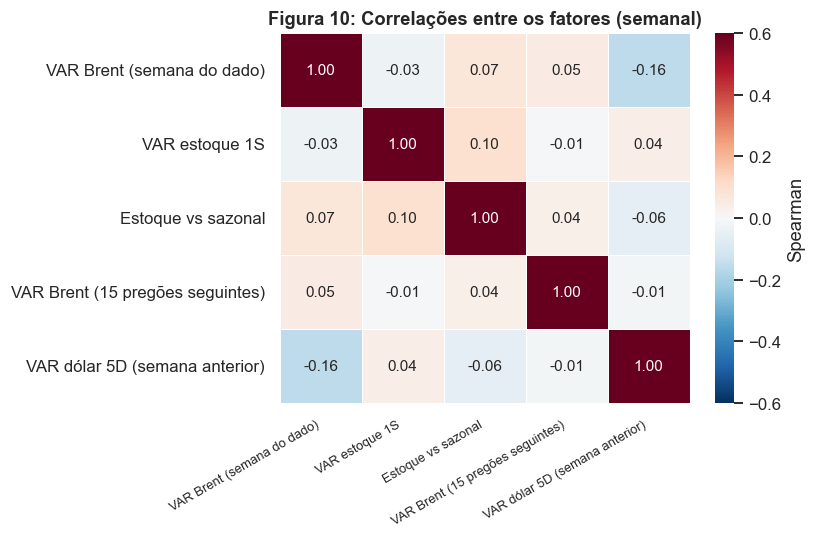

In [14]:
# 3.6 Mapa de correlações entre os fatores (frequência semanal, sem sobreposição)
sm = e2[["VAR_semana_atual", "VAR_1S", "desvio_pct", "VAR_15D_FUT"]].copy()
sm["VAR_dolar_5D"] = np.nan
dsem = dolar.set_index("data")["dolar_amplo"]
sm["VAR_dolar_5D"] = [ (dsem.asof(d1) / dsem.asof(d0) - 1) * 100 for d0, d1 in zip(e2["semana_ref"] - pd.Timedelta(days=7), e2["semana_ref"]) ]
sm = sm.rename(columns={"VAR_semana_atual": "VAR Brent (semana do dado)", "VAR_1S": "VAR estoque 1S", "desvio_pct": "Estoque vs sazonal",
                        "VAR_15D_FUT": "VAR Brent (15 pregões seguintes)", "VAR_dolar_5D": "VAR dólar 5D (semana anterior)"})
fig, ax = plt.subplots(figsize=(7.4, 5.0))
sns.heatmap(sm.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"label": "Spearman"})
ax.set_title("Figura 10: Correlações entre os fatores (semanal)"); ax.tick_params(axis="x", rotation=30, labelsize=8.5)
plt.setp(ax.get_xticklabels(), ha="right"); plt.tight_layout(); plt.show()

## Bloco 4. Padrões: tendência, sazonalidade de calendário e memória

Decidimos na Fase 1 se as **features de calendário** (mês, trimestre, semana do ano, dia da semana) têm base empírica, e como a série "lembra" do passado.

### 4.1 Decomposição em tendência e sazonalidade (STL)

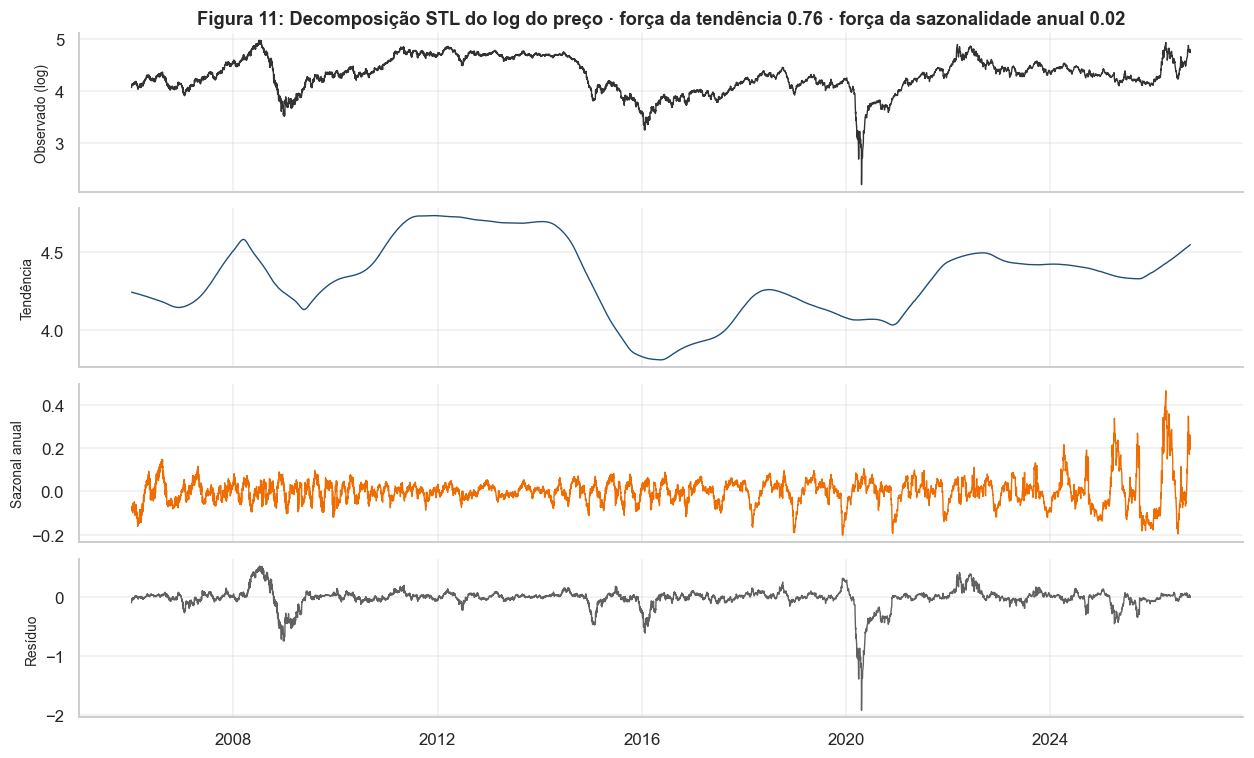

Força da tendência: 0.758 | Força da sazonalidade anual: 0.018 (0 = nenhuma, 1 = total)
Amplitude do componente sazonal anual: 66.6% (em log), contra 92% da tendência


In [15]:
# 4.1 STL do log-preço: ciclo anual (252 pregões)
lp = pd.Series(np.log(y), index=D)
stl = STL(lp, period=252, robust=True).fit()
vr, vt, vs = stl.resid.var(), stl.trend.var(), stl.seasonal.var()
forca_tend = max(0, 1 - vr / (vt + vr)) if False else max(0, 1 - vr / np.var(stl.trend + stl.resid))
forca_saz  = max(0, 1 - vr / np.var(stl.seasonal + stl.resid))

fig, eixos = plt.subplots(4, 1, figsize=(11.5, 7.0), sharex=True)
for eixo, (nome, serie, cor) in zip(eixos, [("Observado (log)", stl.observed, "#333333"), ("Tendência", stl.trend, AZUL), ("Sazonal anual", stl.seasonal, LARANJA), ("Resíduo", stl.resid, CINZA)]):
    eixo.plot(serie.index, serie.values, lw=0.9, color=cor); eixo.set_ylabel(nome, fontsize=9)
eixos[0].set_title(f"Figura 11: Decomposição STL do log do preço · força da tendência {forca_tend:.2f} · força da sazonalidade anual {forca_saz:.2f}")
plt.tight_layout(); plt.show()
amp_saz = (stl.seasonal.max() - stl.seasonal.min()) * 100
print(f"Força da tendência: {forca_tend:.3f} | Força da sazonalidade anual: {forca_saz:.3f} (0 = nenhuma, 1 = total)")
print(f"Amplitude do componente sazonal anual: {amp_saz:.1f}% (em log), contra {(stl.trend.max()-stl.trend.min())*100:.0f}% da tendência")